# Case 2: Multi-Objective Container & Replica Optimization (Horizontal + Vertical Scaling)

In **Case 1** (`container_queue_model.py`), we optimized a **single container** ($N = 1$) by scaling its CPU ($\in [500, 2000]\text{ mCPU}$) and RAM vertically. However, vertical scaling alone has two major limitations:
1. **Upper Bound Saturation**: Once traffic exceeds $\lambda = 140\text{ req/s}$ (for $W_{\max} = 50\text{ ms}$), a single $2000\text{ mCPU}$ container is physically unable to meet the SLA.
2. **Large Single-Container Footprint**: Running one massive container at the top of its CPU/RAM limits can be harder to schedule on fragmented cluster nodes than running a few smaller replicas.

In **Case 2** (`container_replicas_queue_model.py`), we extend the model to jointly optimize **vertical scaling** ($\text{CPU}, \text{RAM}$ per container) and **horizontal scaling** (number of replicas $N \in \{1, 2, 3, 4, 5\}$) with **two competing objectives**:
- **Objective 1 ($f_1$)**: Minimize allocated resources per container ($\text{CPU}$ and $\text{RAM}$).
- **Objective 2 ($f_2$)**: Minimize the number of active container replicas ($N$).

## 1. Mathematical Formulation (MILP)

When a load balancer distributes a Poisson arrival stream $\lambda$ evenly across $N \in \{1, \dots, 5\}$ identical containers, each replica acts as an **M/M/1 queue** with arrival rate:
$$\lambda_{\text{rep}} = \frac{\lambda}{N}$$

### Constraints
1. **Service Capacity per Replica**: $\mu = \alpha_{\text{cpu}} \cdot \text{CPU}$
2. **RAM Provisioning per Replica**: $\text{RAM} \ge \text{RAM}_{\text{base}} + \beta_{\text{ram}} \cdot \mu$
3. **M/M/1 Latency SLA per Replica ($W \le W_{\max}$)**:
   $$W = \frac{1}{\mu - \lambda / N} \le W_{\max} \iff \mu - \frac{\lambda}{N} \ge \frac{1}{W_{\max}}$$
4. **Exact Linearization (MILP)**: Using binary selection variables $z_n \in \{0, 1\}$ for $n \in \{1, \dots, 5\}$:
   $$\sum_{n=1}^{5} z_n = 1, \quad N = \sum_{n=1}^{5} n \cdot z_n, \quad \frac{\lambda}{N} = \sum_{n=1}^{5} \left(\frac{\lambda}{n}\right) z_n$$

### Multi-Objective Function
$$\min_{\text{CPU}, \text{RAM}, N} \quad w_{\text{resources}} \underbrace{\left(w_{\text{cpu}} \frac{\text{CPU}}{\text{CPU}_{\max}} + w_{\text{ram}} \frac{\text{RAM}}{\text{RAM}_{\max}}\right)}_{f_1:\text{ Per-Container Resources}} \;+\; w_{\text{replicas}} \underbrace{\left(\frac{N}{N_{\max}}\right)}_{f_2:\text{ Replica Count}}$$

In [1]:
import os
ASSETS_DIR = os.path.join("assets", "part2") if os.path.exists("assets") else os.path.join("..", "assets", "part2")
os.makedirs(ASSETS_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

from container_replicas_queue_model import (
    build_container_replicas_model,
    solve_replicas_model,
    print_replicas_solution,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

## 2. Solving the Baseline Scenario ($\lambda = 120\text{ req/s}$)

Let's solve the multi-objective model for a total workload of $\lambda = 120\text{ req/s}$, latency SLA $W_{\max} = 50\text{ ms}$, and equal weights ($w_{\text{resources}} = 1.0, w_{\text{replicas}} = 1.0$).

In [2]:
model = build_container_replicas_model(
    lambda_req=120.0,
    w_max=0.05,
    alpha_cpu=0.08,
    ram_base=128.0,
    beta_ram=4.0,
    cpu_bounds=(500.0, 2000.0),
    replica_bounds=(1, 5),
    w_resources=1.0,
    w_replicas=1.0,
)

solve_replicas_model(model)
print_replicas_solution(model)

  CASE 2: MULTI-OBJECTIVE CONTAINER & REPLICA OPTIMIZATION PROBLEM
Workload, SLA & System Parameters:
  Total Arrival Rate (lambda)       : 120.00 req/s
  Max Response Time SLA (W_max)     : 50.00 ms (0.0500 s)
  CPU Throughput (alpha_cpu)        : 0.0800 req/s per millicore
  Base RAM Overhead (ram_base)      : 128.00 MB per container
  Working RAM Factor (beta_ram)     : 4.00 MB per (req/s)
  Allowed Replicas Bounds (N)       : [1, 5] containers
  Per-Container CPU Bounds          : [500, 2000] millicores
  Per-Container RAM Bounds          : [128, 4096] MB
  Multi-Objective Weights           : w_resources=1.00 (w_cpu=1.0, w_ram=1.0), w_replicas=1.00
************************************************************************
  OPTIMAL SOLUTION FOUND
************************************************************************
Optimal Scaling & Load Balancing Decision (Horizontal + Vertical):
  Active Replicas (N) [Obj 2]       : 2 containers (bounds: [1, 5])
  Arrival Rate per Replica (lam/N

## 3. Exploring the Pareto Front: Objective 1 (Container Size) vs. Objective 2 (Replicas)

Why did the solver choose $N^* = 2$ replicas with $1000\text{ mCPU}$ each instead of $N = 1$ or $N = 5$?

Let's evaluate every replica count $N \in \{1, 2, 3, 4, 5\}$ at $\lambda = 120\text{ req/s}$ (using the $\varepsilon$-constraint / fixed-$N$ method) and also sweep the weight ratio $w_{\text{replicas}} / w_{\text{resources}}$ to see how the solver transitions along the **Pareto Front**.

In [3]:
pareto_rows = []
for n_fixed in range(1, 6):
    m = build_container_replicas_model(
        lambda_req=120.0,
        w_max=0.05,
        replica_bounds=(1, 5),
        fixed_replicas=n_fixed,
    )
    solve_replicas_model(m)
    pareto_rows.append({
        "Replicas (N)": n_fixed,
        "Traffic/Replica (req/s)": pyo.value(m.lambda_per_replica),
        "CPU/Container (mCPU)": pyo.value(m.cpu),
        "RAM/Container (MB)": pyo.value(m.ram),
        "Total Cluster CPU (mCPU)": pyo.value(m.total_cluster_cpu),
        "Total Cluster RAM (MB)": pyo.value(m.total_cluster_ram),
        "Utilization (%)": pyo.value(m.utilization) * 100.0,
        "Obj 1 (Resources)": pyo.value(m.obj_resources),
        "Obj 2 (Replicas)": pyo.value(m.obj_replicas),
    })

df_pareto = pd.DataFrame(pareto_rows)
df_pareto

,Replicas (N),Traffic/Replica (req/s),CPU/Container (mCPU),RAM/Container (MB),Total Cluster CPU (mCPU),Total Cluster RAM (MB),Utilization (%),Obj 1 (Resources),Obj 2 (Replicas)
0,1,120.0,1750.0,688.0,1750.0,688.0,85.714286,1.042969,0.2
1,2,60.0,1000.0,448.0,2000.0,896.0,75.000000,0.609375,0.4
2,3,40.0,750.0,368.0,2250.0,1104.0,66.666667,0.464844,0.6
3,4,30.0,625.0,328.0,2500.0,1312.0,60.000000,0.392578,0.8
4,5,24.0,550.0,304.0,2750.0,1520.0,54.545455,0.349219,1.0


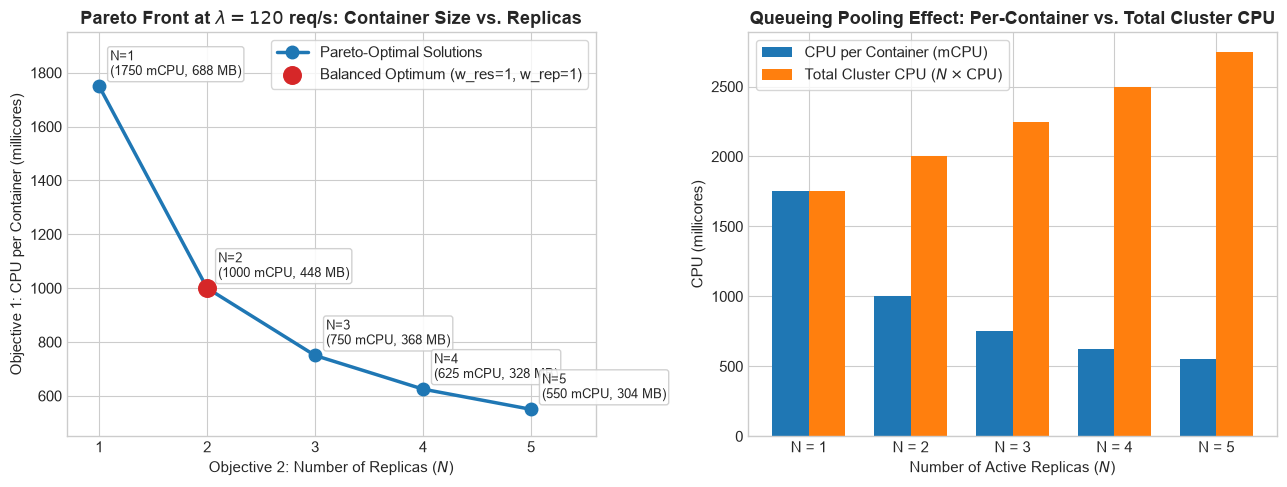

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Pareto Front in Objective Space (Obj 2 vs Obj 1)
ax1 = axes[0]
ax1.plot(df_pareto["Replicas (N)"], df_pareto["CPU/Container (mCPU)"],
         marker="o", markersize=9, lw=2.5, color="#1f77b4", label="Pareto-Optimal Solutions")

for _, row in df_pareto.iterrows():
    n_int = int(row["Replicas (N)"])
    cpu_v = row["CPU/Container (mCPU)"]
    ram_v = row["RAM/Container (MB)"]
    ax1.annotate(
        f"N={n_int}\n({cpu_v:.0f} mCPU, {ram_v:.0f} MB)",
        xy=(n_int, cpu_v),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#cccccc", alpha=0.9),
    )

ax1.scatter([2], [1000], color="#d62728", s=160, zorder=5, label="Balanced Optimum (w_res=1, w_rep=1)")
ax1.set_xticks([1, 2, 3, 4, 5])
ax1.set_xlim(0.7, 5.6)
ax1.set_ylim(450, 1950)
ax1.set_title(r"Pareto Front at $\lambda = 120$ req/s: Container Size vs. Replicas", fontweight="bold")
ax1.set_xlabel("Objective 2: Number of Replicas ($N$)")
ax1.set_ylabel("Objective 1: CPU per Container (millicores)")
ax1.legend(loc="upper right", frameon=True)

# Right: Per-Container CPU vs Total Cluster CPU as N increases
ax2 = axes[1]
x = np.arange(len(df_pareto))
width = 0.36

b1 = ax2.bar(x - width/2, df_pareto["CPU/Container (mCPU)"], width, label="CPU per Container (mCPU)", color="#1f77b4")
b2 = ax2.bar(x + width/2, df_pareto["Total Cluster CPU (mCPU)"], width, label=r"Total Cluster CPU ($N \times \mathrm{CPU}$)", color="#ff7f0e")

ax2.set_xticks(x)
ax2.set_xticklabels([f"N = {n}" for n in df_pareto["Replicas (N)"]])
ax2.set_title("Queueing Pooling Effect: Per-Container vs. Total Cluster CPU", fontweight="bold")
ax2.set_xlabel("Number of Active Replicas ($N$)")
ax2.set_ylabel("CPU (millicores)")
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "01_pareto_replicas_tradeoff.png"), dpi=150, bbox_inches="tight")
plt.show()

### Key Queueing Insights from the Pareto Front
1. **Convex Trade-Off Between Vertical and Horizontal Scaling**:
   - Moving from $N=1 \to N=2$ cuts per-container CPU dramatically from **$1750\text{ mCPU}$ down to $1000\text{ mCPU}$** (saving $750\text{ mCPU}$ per container).
   - Moving from $N=4 \to N=5$ only reduces per-container CPU from **$625\text{ mCPU}$ to $550\text{ mCPU}$** (diminishing returns of $1/N$).
2. **Why Fewer Replicas Save Total Cluster CPU & RAM (Queueing Pooling)**:
   - Look at the orange bars on the right: **Total Cluster CPU** increases linearly with $N$: $\text{CPU}_{\text{cluster}}(N) = \frac{\lambda + N / W_{\max}}{\alpha_{\text{cpu}}} = 1500 + 250 N\text{ mCPU}$.
   - Because each replica operates as an independent M/M/1 queue, **every additional replica requires its own $20\text{ req/s}$ ($250\text{ mCPU}$) latency safety buffer** and its own $128\text{ MB}$ base RAM overhead! That is why penalizing replica count ($N$) in Objective 2 is essential both for cluster overhead and total resource efficiency.

## 4. Joint Horizontal & Vertical Autoscaling Across Traffic Loads ($\lambda$)

Now let's sweep the total incoming traffic $\lambda$ from $10\text{ req/s}$ all the way up to $550\text{ req/s}$ (where a single container would fail above $140\text{ req/s}$) and observe how the optimizer coordinates **Vertical Scaling (CPU/RAM)** and **Horizontal Scaling (Replicas $N$)**.

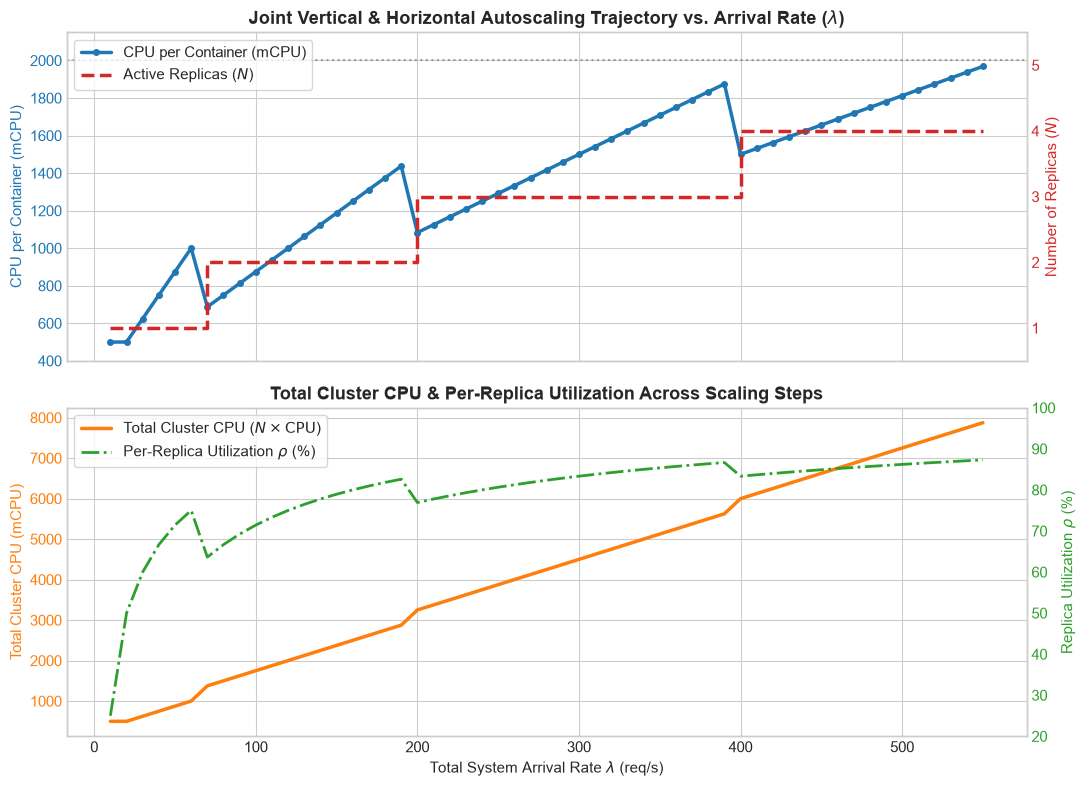

In [5]:
traffic_grid = np.linspace(10, 550, 55)
scaling_rows = []

for lam in traffic_grid:
    m = build_container_replicas_model(
        lambda_req=float(lam),
        w_max=0.05,
        alpha_cpu=0.08,
        ram_base=128.0,
        beta_ram=4.0,
        cpu_bounds=(500.0, 2000.0),
        replica_bounds=(1, 5),
        w_resources=1.0,
        w_replicas=1.2,
    )
    solve_replicas_model(m)
    scaling_rows.append({
        "lambda_req": lam,
        "replicas": int(round(pyo.value(m.replicas))),
        "cpu_per_container": pyo.value(m.cpu),
        "ram_per_container": pyo.value(m.ram),
        "total_cluster_cpu": pyo.value(m.total_cluster_cpu),
        "utilization_pct": pyo.value(m.utilization) * 100.0,
    })

df_scale = pd.DataFrame(scaling_rows)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# Top Plot: Per-Container CPU (Sawtooth) & Active Replicas Step Function
ax1 = axes[0]
l1 = ax1.plot(df_scale["lambda_req"], df_scale["cpu_per_container"], color="#1f77b4", lw=2.5,
              marker="o", markersize=4, label="CPU per Container (mCPU)")
ax1.axhline(2000, color="gray", ls=":", alpha=0.7, label="Max CPU per Container (2000 mCPU)")
ax1.set_ylabel("CPU per Container (mCPU)", color="#1f77b4")
ax1.tick_params(axis="y", labelcolor="#1f77b4")
ax1.set_ylim(400, 2150)

ax1_rep = ax1.twinx()
l2 = ax1_rep.step(df_scale["lambda_req"], df_scale["replicas"], where="post", color="#d62728",
                  lw=2.5, ls="--", label="Active Replicas ($N$)")
ax1_rep.set_ylabel("Number of Replicas ($N$)", color="#d62728")
ax1_rep.tick_params(axis="y", labelcolor="#d62728")
ax1_rep.set_yticks([1, 2, 3, 4, 5])
ax1_rep.set_ylim(0.5, 5.5)
ax1_rep.grid(False)

lines = l1 + l2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)
ax1.set_title(r"Joint Vertical & Horizontal Autoscaling Trajectory vs. Arrival Rate ($\lambda$)", fontweight="bold")

# Bottom Plot: Total Cluster CPU and Per-Replica Utilization
ax2 = axes[1]
l3 = ax2.plot(df_scale["lambda_req"], df_scale["total_cluster_cpu"], color="#ff7f0e", lw=2.5,
              label=r"Total Cluster CPU ($N \times \mathrm{CPU}$)")
ax2.set_xlabel(r"Total System Arrival Rate $\lambda$ (req/s)")
ax2.set_ylabel("Total Cluster CPU (mCPU)", color="#ff7f0e")
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

ax2_u = ax2.twinx()
l4 = ax2_u.plot(df_scale["lambda_req"], df_scale["utilization_pct"], color="#2ca02c", lw=2.0,
                ls="-.", label=r"Per-Replica Utilization $\rho$ (%)")
ax2_u.set_ylabel(r"Replica Utilization $\rho$ (%)", color="#2ca02c")
ax2_u.tick_params(axis="y", labelcolor="#2ca02c")
ax2_u.set_ylim(20, 100)
ax2_u.grid(False)

lines2 = l3 + l4
labels2 = [line.get_label() for line in lines2]
ax2.legend(lines2, labels2, loc="upper left", frameon=True)
ax2.set_title("Total Cluster CPU & Per-Replica Utilization Across Scaling Steps", fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "02_traffic_scaling_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

### Interpreting the Sawtooth Autoscaling Pattern
- **Vertical Scaling Within Each Plateau**: For a fixed replica count $N$, as traffic $\lambda$ rises, the optimizer scales CPU and RAM **vertically** (blue curve rises).
- **Horizontal Scale-Out Events (Red Steps)**: Whenever per-container resources become too expensive relative to adding a replica (or when a container approaches its $2000\text{ mCPU}$ ceiling), the optimizer increments $N \to N + 1$. Immediately upon adding a replica, the load per container drops from $\frac{\lambda}{N}$ to $\frac{\lambda}{N+1}$, allowing **per-container CPU and RAM to scale down** (creating the characteristic sawtooth pattern).
- **Expanded System Capacity**: While Case 1 ($N=1$) maxed out at $\lambda = 140\text{ req/s}$, Case 2 ($N \le 5$) smoothly handles up to **$\lambda = 700\text{ req/s}$** ($5 \times 140\text{ req/s}$) while maintaining the $50\text{ ms}$ mean response time SLA.

## 5. Decision Map: Optimal Replica Count $N^*$ Across Workload ($\lambda$) and Preference Weights ($w_{\text{replicas}}$)

Finally, let's build a 2D decision map showing which replica count $N^* \in \{1, 2, 3, 4, 5\}$ is optimal as a function of:
1. **Total Arrival Rate $\lambda$** ($x$-axis)
2. **Replica Penalty Weight $w_{\text{replicas}}$** ($y$-axis, keeping $w_{\text{resources}} = 1.0$)

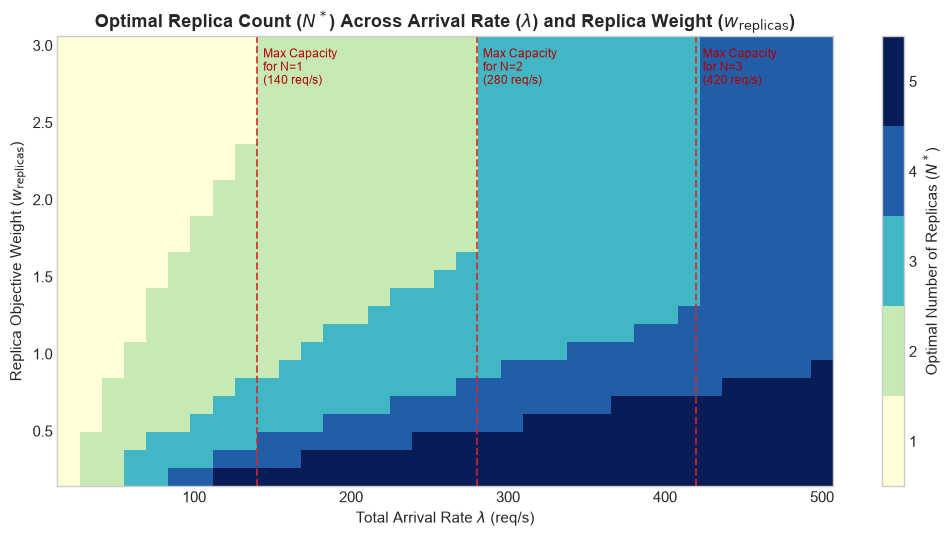

In [6]:
lam_vals = np.linspace(20, 500, 35)
w_rep_vals = np.linspace(0.2, 3.0, 25)
N_grid = np.zeros((len(w_rep_vals), len(lam_vals)))

for i, w_rep in enumerate(w_rep_vals):
    for j, lam in enumerate(lam_vals):
        m = build_container_replicas_model(
            lambda_req=float(lam),
            w_max=0.05,
            w_resources=1.0,
            w_replicas=float(w_rep),
        )
        solve_replicas_model(m)
        N_grid[i, j] = int(round(pyo.value(m.replicas)))

fig, ax = plt.subplots(figsize=(10.5, 5.5))
cmap = plt.get_cmap("YlGnBu", 5)
im = ax.pcolormesh(lam_vals, w_rep_vals, N_grid, cmap=cmap, vmin=0.5, vmax=5.5, shading="auto")

cbar = plt.colorbar(im, ax=ax, ticks=[1, 2, 3, 4, 5])
cbar.set_label("Optimal Number of Replicas ($N^*$)")

# Mark hard capacity boundaries (multiples of 140 req/s)
for k in range(1, 4):
    ax.axvline(k * 140, color="#d62728", ls="--", lw=1.4, alpha=0.85)
    ax.text(k * 140 + 4, 2.75, f"Max Capacity\nfor N={k}\n({k*140} req/s)", color="#b30000", fontsize=8.5)

ax.set_title(r"Optimal Replica Count ($N^*$) Across Arrival Rate ($\lambda$) and Replica Weight ($w_{\mathrm{replicas}}$)", fontweight="bold")
ax.set_xlabel(r"Total Arrival Rate $\lambda$ (req/s)")
ax.set_ylabel(r"Replica Objective Weight ($w_{\mathrm{replicas}}$)")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "03_cluster_overhead_breakdown.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Detailed Problem Search Space ($N \times \text{CPU} \times \text{RAM}$)

In **Case 2**, the search space is a **mixed-integer 3D domain** $\Omega = \{1, 2, 3, 4, 5\} \times [500, 2000]\text{ mCPU} \times [128, 4096]\text{ MB}$. Because the total arrival rate $\lambda = 120\text{ req/s}$ is divided equally among the $N$ active replicas ($\lambda_{\text{rep}} = \frac{\lambda}{N}$), each discrete slice $N \in \{1, \dots, 5\}$ induces its own M/M/1 SLA boundary:

$$
\text{CPU}_{\min}(N) = \max\!\left(500,\; \frac{\frac{\lambda}{N} + \frac{1}{W_{\max}}}{\alpha_{\text{cpu}}}\right)
$$

Below, we visualize:
- **Left Panel (2D Search Space Slices Across $N=1\dots 5$)**: Shows how increasing $N$ shifts the vertical SLA boundary to the left, expanding the feasible region in the $(\text{CPU}, \text{RAM})$ plane and moving the per-slice optimal vertex $(N, \text{CPU}^*(N), \text{RAM}^*(N))$.
- **Right Panel (3D Mixed-Integer Search Space)**: Displays the 5 discrete feasible planes stacked along the integer replica axis $N$, highlighting the candidate optimal vertices for each $N$ and the global multi-objective optimum at $N^* = 2$.

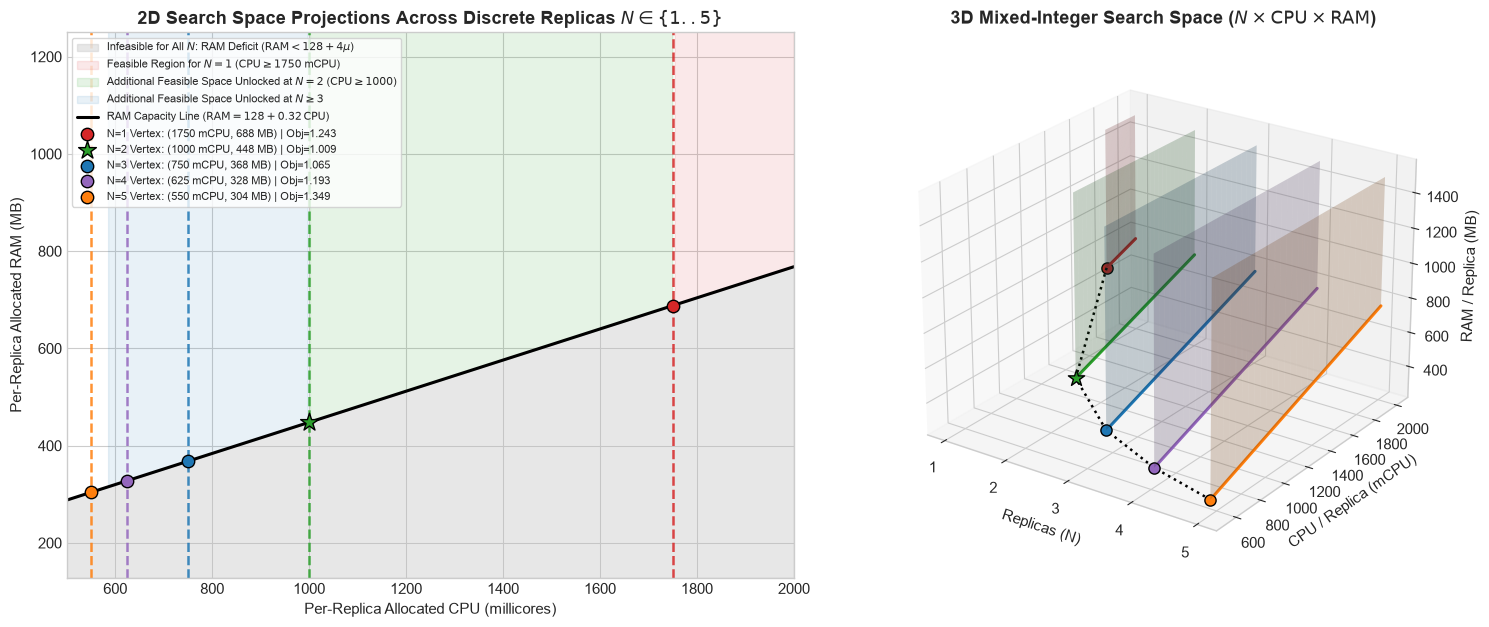

In [7]:
# TODO Crie um grafico detalhando o espaco de busca do problema
cpu_vec = np.linspace(500, 2000, 300)
ram_req_vec = 128.0 + 4.0 * (0.08 * cpu_vec)

slice_colors = {
    1: "#d62728",
    2: "#2ca02c",
    3: "#1f77b4",
    4: "#9467bd",
    5: "#ff7f0e",
}

fig = plt.figure(figsize=(15.5, 6.4))

# --- Panel 1: 2D Search Space & Shifting SLA Boundaries per Replica Count N ---
ax1 = fig.add_subplot(1, 2, 1)

# Shade RAM deficit region (infeasible for all N)
ax1.fill_between(
    cpu_vec, 128, ram_req_vec,
    color="#bdbdbd", alpha=0.35,
    label=r"Infeasible for All $N$: RAM Deficit ($\mathrm{RAM} < 128 + 4\mu$)"
)

# Shade feasible region for N=1 (strictest feasible slice: CPU >= 1750)
ax1.fill_between(
    cpu_vec, ram_req_vec, 1400,
    where=(cpu_vec >= 1750),
    color="#d62728", alpha=0.10,
    label=r"Feasible Region for $N=1$ ($\mathrm{CPU} \geq 1750$ mCPU)"
)

# Shade additional feasible region unlocked by N=2 (1000 <= CPU <= 1750)
ax1.fill_between(
    cpu_vec, ram_req_vec, 1400,
    where=(cpu_vec >= 1000) & (cpu_vec <= 1750),
    color="#2ca02c", alpha=0.12,
    label=r"Additional Feasible Space Unlocked at $N=2$ ($\mathrm{CPU} \geq 1000$)"
)

# Shade additional feasible region unlocked by N>=3 (CPU >= 583.33)
ax1.fill_between(
    cpu_vec, ram_req_vec, 1400,
    where=(cpu_vec >= 583.33) & (cpu_vec <= 1000),
    color="#1f77b4", alpha=0.10,
    label=r"Additional Feasible Space Unlocked at $N \geq 3$"
)

ax1.plot(cpu_vec, ram_req_vec, color="black", lw=2.2, label=r"RAM Capacity Line ($\mathrm{RAM} = 128 + 0.32\,\mathrm{CPU}$)")

# Plot vertical SLA boundary and optimal vertex for each N in {1..5}
for _, row in df_pareto.iterrows():
    n_val = int(row["Replicas (N)"])
    c_opt = row["CPU/Container (mCPU)"]
    r_opt = row["RAM/Container (MB)"]
    f_tot = (row["Obj 1 (Resources)"] + row["Obj 2 (Replicas)"])
    col = slice_colors[n_val]

    ax1.axvline(c_opt, color=col, ls="--", lw=1.8, alpha=0.85)
    marker = "*" if n_val == 2 else "o"
    size = 180 if n_val == 2 else 80
    ax1.scatter(
        [c_opt], [r_opt], color=col, s=size, marker=marker, zorder=6, edgecolors="black",
        label=f"N={n_val} Vertex: ({c_opt:.0f} mCPU, {r_opt:.0f} MB) | Obj={f_tot:.3f}"
    )

ax1.set_xlim(500, 2000)
ax1.set_ylim(128, 1250)
ax1.set_title(r"2D Search Space Projections Across Discrete Replicas $N \in \{1..5\}$", fontweight="bold")
ax1.set_xlabel("Per-Replica Allocated CPU (millicores)")
ax1.set_ylabel("Per-Replica Allocated RAM (MB)")
ax1.legend(loc="upper left", fontsize=7.8, frameon=True)

# --- Panel 2: 3D Mixed-Integer Search Space (N x CPU x RAM) ---
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

for _, row in df_pareto.iterrows():
    n_val = int(row["Replicas (N)"])
    c_min = row["CPU/Container (mCPU)"]
    r_min = row["RAM/Container (MB)"]
    col = slice_colors[n_val]

    # Create feasible strip on discrete plane N = n_val
    c_seg = np.linspace(c_min, 2000, 30)
    r_low = 128.0 + 0.32 * c_seg
    r_high = np.full_like(c_seg, 1500.0)

    C_plane = np.vstack([c_seg, c_seg])
    R_plane = np.vstack([r_low, r_high])
    N_plane = np.full_like(C_plane, float(n_val))

    ax2.plot_surface(N_plane, C_plane, R_plane, color=col, alpha=0.22, edgecolor="none")
    ax2.plot(np.full_like(c_seg, n_val), c_seg, r_low, color=col, lw=2.2)

    # Candidate optimum on slice N
    marker = "*" if n_val == 2 else "o"
    sz = 150 if n_val == 2 else 65
    ax2.scatter([n_val], [c_min], [r_min], color=col, s=sz, marker=marker, edgecolors="black", depthshade=False)

# Connect candidate vertices across N=1..5
ax2.plot(
    df_pareto["Replicas (N)"], df_pareto["CPU/Container (mCPU)"], df_pareto["RAM/Container (MB)"],
    color="black", ls=":", lw=1.8, label="Pareto Candidate Trajectory"
)

ax2.set_xticks([1, 2, 3, 4, 5])
ax2.set_title(r"3D Mixed-Integer Search Space ($N \times \mathrm{CPU} \times \mathrm{RAM}$)", fontweight="bold")
ax2.set_xlabel("Replicas (N)")
ax2.set_ylabel("CPU / Replica (mCPU)")
ax2.set_zlabel("RAM / Replica (MB)")
ax2.view_init(elev=24, azim=-55)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "04_3d_multiobjective_surface.png"), dpi=150, bbox_inches="tight")
plt.show()